# Исследовательский анализ бронирований отелей

## Цель

В проекте изучим отмены бронирований, сравним City Hotel и Resort Hotel, рассчитаем бизнес-метрики и найдём признаки, связанные с отменой.

Основные вопросы:

- какова доля отмен;
- где отмен больше;
- как отмены связаны с типом отеля, сегментом, депозитом и `lead_time`;
- какая доля потенциальной стоимости приходится на неотменённые бронирования.

In [484]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
np.random.seed(42)
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 50) 
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. Загрузка данных

Загрузим `hotel_bookings.csv` и проверим первые строки.

In [485]:
df = pd.read_csv('hotel_bookings.csv')
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.00,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.00,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.00,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03


**Размер данных:** 119 390 строк и 32 столбца. Даты пока хранятся как строки.

In [486]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [487]:
df.columns.to_list()

['hotel',
 'is_canceled',
 'lead_time',
 'arrival_date_year',
 'arrival_date_month',
 'arrival_date_week_number',
 'arrival_date_day_of_month',
 'stays_in_weekend_nights',
 'stays_in_week_nights',
 'adults',
 'children',
 'babies',
 'meal',
 'country',
 'market_segment',
 'distribution_channel',
 'is_repeated_guest',
 'previous_cancellations',
 'previous_bookings_not_canceled',
 'reserved_room_type',
 'assigned_room_type',
 'booking_changes',
 'deposit_type',
 'agent',
 'company',
 'days_in_waiting_list',
 'customer_type',
 'adr',
 'required_car_parking_spaces',
 'total_of_special_requests',
 'reservation_status',
 'reservation_status_date']

## 2. Качество данных

Основные пропуски находятся в `company` (94,3%), `agent` (13,7%), `country` (0,4%) и `children` (4 значения).

In [488]:
df.isna().mean().to_frame()

,0
hotel,0.00
is_canceled,0.00
lead_time,0.00
arrival_date_year,0.00
arrival_date_month,0.00
arrival_date_week_number,0.00
arrival_date_day_of_month,0.00
stays_in_weekend_nights,0.00
stays_in_week_nights,0.00
adults,0.00


In [489]:
df[df.duplicated()]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.00,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.00,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,A,A,1,No Deposit,250.00,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,0.00,0,HB,ROU,Direct,Direct,0,0,0,E,E,0,No Deposit,250.00,NaN,0,Transient,137.00,0,1,Check-Out,2015-07-07
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,0.00,0,BB,PRT,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,240.00,NaN,0,Transient,97.00,0,0,Canceled,2015-07-01
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,0.00,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.00,NaN,0,Transient,109.80,0,3,Check-Out,2015-07-08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119349,City Hotel,0,186,2017,August,35,31,0,3,2,0.00,0,BB,DEU,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,9.00,NaN,0,Transient,126.00,0,2,Check-Out,2017-09-03
119352,City Hotel,0,63,2017,August,35,31,0,3,3,0.00,0,BB,SWE,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,9.00,NaN,0,Transient-Party,195.33,0,2,Check-Out,2017-09-03
119353,City Hotel,0,63,2017,August,35,31,0,3,3,0.00,0,BB,SWE,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,9.00,NaN,0,Transient-Party,195.33,0,2,Check-Out,2017-09-03
119354,City Hotel,0,63,2017,August,35,31,0,3,3,0.00,0,BB,SWE,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,9.00,NaN,0,Transient-Party,195.33,0,2,Check-Out,2017-09-03


### Обработка пропусков

- `children` заменим на 0;
- `company`, `agent` и `country` — на `Unknown`.

Строки из-за этих пропусков удалять не будем.

In [490]:
df["company"] = df["company"].fillna("Unknown")
df["children"] = df["children"].fillna(0)

In [491]:
len(df[df["company"].isna()])

0

In [492]:
df.duplicated().sum()

np.int64(31994)

### Дубликаты

Найдено 31 994 одинаковые строки. Уникального ID бронирования нет, поэтому дубликаты оставим: это могут быть разные бронирования с одинаковыми параметрами.

In [493]:
df["reservation_status_date"] = pd.to_datetime(df["reservation_status_date"], format="%Y-%m-%d")

In [494]:
df['arrival_date'] = pd.to_datetime(df['arrival_date_year'].astype('str') + '-' 
                                    +df['arrival_date_month'] +'-'
                                    +df['arrival_date_day_of_month'].astype('str'),
                                    format="%Y-%B-%d")

In [495]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,Unknown,0,Transient,0.00,0,0,Check-Out,2015-07-01,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,Unknown,0,Transient,0.00,0,0,Check-Out,2015-07-01,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,Unknown,0,Transient,75.00,0,0,Check-Out,2015-07-02,2015-07-01
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.00,Unknown,0,Transient,75.00,0,0,Check-Out,2015-07-02,2015-07-01
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.00,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.00,Unknown,0,Transient,98.00,0,1,Check-Out,2015-07-03,2015-07-01


## 3. Даты и статусы

Преобразуем даты в `datetime` и проверим статусы: `Check-Out`, `Canceled` и `No-Show`.

In [496]:
status_df = (
    df.groupby("reservation_status", dropna=False)
      .size()
      .reset_index(name="booking_count")
)
status_df

,reservation_status,booking_count
0,Canceled,43017
1,Check-Out,75166
2,No-Show,1207


In [497]:
df['agent'] = df['agent'].fillna("Unknown").astype("str")

In [498]:
df.isna().sum().to_frame()

,0
hotel,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0


In [499]:
df.loc[df["country"].isna(), "country"] = "Unknown"

## 4. Новые признаки

- `total_nights` — общее число ночей;
- `total_guests` — число гостей;
- `room_changed` — отличается ли выданный номер от забронированного.

In [500]:
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_guests'] = df['adults'] + df['children'] + df['babies']
df['room_changed'] = df['reserved_room_type'] != df['assigned_room_type']


## 5. Аномалии

Найдено:

- 180 бронирований без гостей;
- 715 бронирований без ночей;
- 1 отрицательный ADR;
- 1 959 нулевых ADR;
- 1 ADR выше 1 000.

In [501]:
zero_guests = df['total_guests'].where(df['total_guests']==0).count()
zero_nights = df['total_nights'].where(df['total_nights']==0).count()
negative_adr = df['adr'].where(df['adr']<0).count()
zero_adr = df['adr'].where(df['adr']==0).count()
more_1000_adr = df['adr'].where(df['adr']>1000).count()
arr = [['zero_guests', zero_guests], ['zero_nights', zero_nights], ['negative_adr', negative_adr], ['zero_adr', zero_adr], ['more_1000_adr', more_1000_adr]]

In [502]:
show_df = pd.DataFrame(arr, columns=['item', 'count_strs'])
show_df

,item,count_strs
0,zero_guests,180
1,zero_nights,715
2,negative_adr,1
3,zero_adr,1959
4,more_1000_adr,1


In [503]:
df.loc[df['total_guests']==0, ['hotel', 'is_canceled', 'total_nights', 'total_guests', 'adr', 'market_segment', 'customer_type', 'arrival_date']]

,hotel,is_canceled,total_nights,total_guests,adr,market_segment,customer_type,arrival_date
2224,Resort Hotel,0,3,0.00,0.00,Corporate,Transient-Party,2015-10-06
2409,Resort Hotel,0,0,0.00,0.00,Corporate,Transient,2015-10-12
3181,Resort Hotel,0,3,0.00,0.00,Groups,Transient-Party,2015-11-20
3684,Resort Hotel,0,5,0.00,0.00,Groups,Transient-Party,2015-12-30
3708,Resort Hotel,0,6,0.00,0.00,Groups,Transient-Party,2015-12-30
...,...,...,...,...,...,...,...,...
115029,City Hotel,0,3,0.00,100.80,Online TA,Transient,2017-06-27
115091,City Hotel,0,1,0.00,0.00,Complementary,Transient,2017-06-30
116251,City Hotel,0,2,0.00,73.80,Online TA,Transient,2017-07-15
116534,City Hotel,0,7,0.00,22.86,Online TA,Transient-Party,2017-07-15


In [504]:
df.loc[df['adr']<0, ['hotel', 'is_canceled', 'total_nights', 'total_guests', 'adr', 'market_segment', 'customer_type', 'arrival_date']]

,hotel,is_canceled,total_nights,total_guests,adr,market_segment,customer_type,arrival_date
14969,Resort Hotel,0,10,2.00,-6.38,Groups,Transient-Party,2017-03-05


In [505]:
df.loc[df['adr']>1000, ['hotel', 'is_canceled', 'total_nights', 'total_guests', 'adr', 'market_segment', 'customer_type', 'arrival_date']]

,hotel,is_canceled,total_nights,total_guests,adr,market_segment,customer_type,arrival_date
48515,City Hotel,1,1,2.00,"5,400.00",Offline TA/TO,Transient,2016-03-25


In [506]:
df['adr'].loc[df['adr']==5400.0] - df['adr'].mean()

48515   5,298.17
Name: adr, dtype: float64

In [507]:
print(df['adr'].quantile(0.01))
print(df['adr'].quantile(0.25))
print(df['adr'].median())
print(df['adr'].quantile(0.75))
print(df['adr'].quantile(0.99))
print(df['adr'].max())

0.0
69.29
94.575
126.0
252.0
5400.0


### Аналитическая выборка

Удалим бронирования без гостей и строку с отрицательным ADR. Останется 119 209 наблюдений. Нулевые ночи, нулевой ADR и ADR 5 400 оставим, но для типичной цены будем использовать медиану.

In [508]:
analyst_df = df[(df['total_guests']!=0) & (df['adr']>=0)].copy()

## 6. Оценка стоимости бронирований

- `booking_value` = ADR × число ночей;
- `proxy_revenue` — стоимость неотменённых бронирований;
- `revenue_lost` — стоимость отменённых бронирований.

Это приближённые показатели: в данных нет оплат, возвратов, штрафов и дополнительных услуг.

In [509]:
analyst_df['booking_value'] = analyst_df['adr'] * analyst_df['total_nights']
analyst_df['proxy_revenue'] = analyst_df['booking_value'].where(analyst_df['is_canceled'] == 0, 0)
analyst_df['revenue_lost'] = analyst_df['booking_value'].where(analyst_df['is_canceled'] == 1, 0)

## 7. Основные бизнес-метрики

Рассчитаем количество бронирований, доли отмен и No-Show, ADR, длительность проживания и оценочные денежные показатели.

In [510]:
count_booking = len(analyst_df)
count_real_booking = analyst_df['is_canceled'].where(analyst_df['is_canceled'] == 0).count()
canceled_booking = analyst_df['is_canceled'].where(analyst_df['is_canceled'] == 1).count()
canceled_rate = analyst_df['is_canceled'].mean() * 100
completition_rate = (100 - canceled_rate) 
no_show = analyst_df['reservation_status'].loc[analyst_df['reservation_status'] == 'No-Show'].count()
no_show_rate = analyst_df['reservation_status'].loc[analyst_df['reservation_status'] == 'No-Show'].count() / analyst_df['reservation_status'].count() * 100
median_adr = analyst_df['adr'].median()
mean_count_nights = analyst_df['total_nights'].mean()
median_count_nights = analyst_df['total_nights'].median()
booking_value = analyst_df['booking_value'].sum()
proxy_revenue_value = analyst_df['proxy_revenue'].sum()
revenue_lost_value = analyst_df['revenue_lost'].sum()
revenue_realization_rate = analyst_df['proxy_revenue'].sum() / analyst_df['booking_value'].sum() * 100

In [511]:
arr1 = [['Общее количество бронирований', count_booking],
        ['Количество состоявшихся бронирований', count_real_booking],
        ['Количество отмененных бронирований', canceled_booking],
        ['Процент отмененных бронирований', canceled_rate],
        ['Процент состоявшихся бронирований', completition_rate],
        ['No-Show', no_show],
        ['No-Show rate', no_show_rate],
        ['Median ADR', median_adr],
        ['Среднее количество ночей', mean_count_nights],
        ['Медианное количество ночей', median_count_nights],
        ['Booking value', booking_value],
        ['Proxy revenue', proxy_revenue_value],
        ['Revenue lost', revenue_lost_value],
        ['Revenue rate', revenue_realization_rate]]

In [512]:
df2 = pd.DataFrame(arr1, columns=['Метрики', 'Значения'])
df2

,Метрики,Значения
0,Общее количество бронирований,"119,209.00"
1,Количество состоявшихся бронирований,"75,010.00"
2,Количество отмененных бронирований,"44,199.00"
3,Процент отмененных бронирований,37.08
4,Процент состоявшихся бронирований,62.92
5,No-Show,"1,206.00"
6,No-Show rate,1.01
7,Median ADR,94.95
8,Среднее количество ночей,3.43
9,Медианное количество ночей,3.00


### Основные результаты

- бронирований — **119 209**;
- отменено — **44 199 (37,1%)**;
- состоялось — **62,9%**;
- No-Show rate — **1,0%**;
- медианный ADR — **94,95**;
- средняя длительность — **3,43 ночи**;
- потенциальная стоимость — **42,71 млн**;
- стоимость неотменённых бронирований — **25,99 млн (60,8%)**.

Денежная единица в датасете не указана.

## 8. Сравнение отелей

Сравним объём бронирований, отмены, ADR, длительность проживания и стоимость по типам отелей.

In [513]:
grouped_hotel = analyst_df.groupby(by='hotel').agg(bookings=('hotel', 'size'),
                                                   count_canceled=('is_canceled', sum),
                                                   median_adr=('adr', 'median'),
                                                   mean_adr=('adr', 'mean'),
                                                   mean_count_nights=('total_nights', 'mean'),
                                                   revenue_hotel=('booking_value', 'sum'),
                                                   proxy_revenue=('proxy_revenue', 'sum'),
                                                   lost_revenue=('revenue_lost', 'sum')
).reset_index()

In [514]:
grouped_hotel.insert(2, 'real_booking', grouped_hotel['bookings'] - grouped_hotel['count_canceled'])
grouped_hotel.insert(4, 'canceled_rate', grouped_hotel['count_canceled'] / grouped_hotel['bookings'] * 100)
grouped_hotel.insert(5, 'completition_rate', grouped_hotel['real_booking'] / grouped_hotel['bookings'] * 100)
grouped_hotel.insert(8, 'revenue_realization_rate', grouped_hotel['proxy_revenue'] / grouped_hotel['revenue_hotel'] * 100)

In [515]:
grouped_hotel

,hotel,bookings,real_booking,count_canceled,canceled_rate,completition_rate,median_adr,mean_adr,revenue_realization_rate,mean_count_nights,revenue_hotel,proxy_revenue,lost_revenue
0,City Hotel,79163,46084,33079,41.79,58.21,99.96,105.50,56.93,2.97,"25,270,401.78","14,385,342.00","10,885,059.78"
1,Resort Hotel,40046,28926,11120,27.77,72.23,75.00,94.99,66.51,4.32,"17,443,811.37","11,601,634.03","5,842,177.34"


### Результат

City Hotel: 79,2 тыс. бронирований, 41,8% отмен, медианный ADR 99,96. Resort Hotel: 40,0 тыс. бронирований, 27,8% отмен, медианный ADR 75,00. В Resort Hotel проживание дольше, а доля стоимости неотменённых бронирований выше: 66,5% против 56,9%.

## 9. Графики по типам отелей

In [516]:
sns.set_theme(
    style="whitegrid",
    palette="deep",
    context="notebook"
)

### 9.1. Доля отмен

Сравним долю отмен в двух отелях.

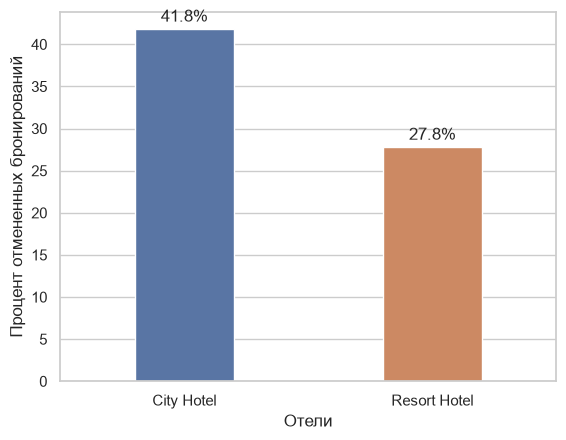

In [517]:
ax = sns.barplot(data=grouped_hotel, 
            x='hotel', 
            y='canceled_rate', 
            hue='hotel',
            width=0.4, 
            palette='deep',
            errorbar=None)

for x in ax.containers:
    ax.bar_label(x, 
                 fmt='%.1f%%',
                 padding=3,
)
plt.ylabel('Процент отмененных бронирований')
plt.xlabel('Отели')
plt.show()


**Вывод:** в City Hotel отменяется около 42 бронирований из 100, в Resort Hotel — около 28.

### 9.2. Доля стоимости неотменённых бронирований

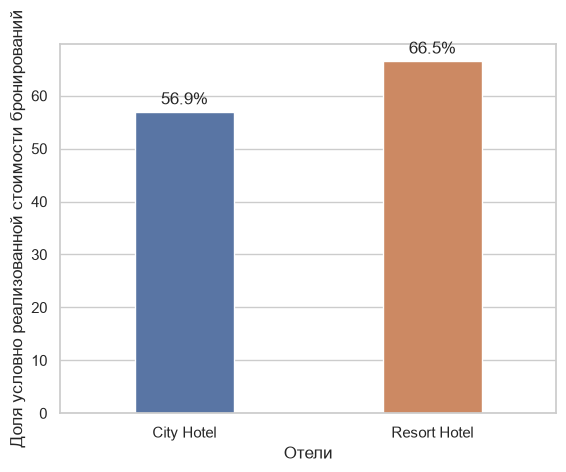

In [518]:
ax = sns.barplot(data=grouped_hotel,
                 x='hotel',
                 y='revenue_realization_rate',
                 hue='hotel',
                 palette='deep',
                 width=0.4,
                 errorbar=None)

for x in ax.containers:
    ax.bar_label(x,
                 fmt='%.1f%%',
                 padding=3)
plt.ylabel('Доля условно реализованной стоимости бронирований')
plt.xlabel('Отели')
plt.show()

**Вывод:** Resort Hotel сохраняет 66,5% потенциальной стоимости, City Hotel — 56,9%.

## 10. Динамика по месяцам

Сравним число бронирований, долю отмен, медианный ADR и стоимость неотменённых бронирований. 2015 и 2017 годы неполные, поэтому годовые суммы напрямую сравнивать не будем.

In [519]:
analyst_df['arrival_period'] = pd.to_datetime(analyst_df['arrival_date_year'].astype('str')+'-'+analyst_df['arrival_date_month'], format='%Y-%B')

In [520]:
analyst_df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date', 'arrival_date',
       'total_nights', 'total_guests', 'room_changed', 'booking_value',
       'proxy_revenue', 'revenue_lost', 'arrival_period'],
      dtype='str')

In [521]:
grouped_time_hotel = analyst_df.groupby(['arrival_period', 'hotel']).agg(
                                        count_booking=('hotel', 'size'),
                                        count_canceled=('is_canceled', 'sum'),
                                        median_adr=('adr', 'median'),
                                        sum_proxy=('proxy_revenue', 'sum')
)

grouped_time_hotel['canceled_rate'] = grouped_time_hotel['count_canceled'] / grouped_time_hotel['count_booking'] * 100

In [522]:
grouped_time_hotel

count_booking  count_canceled  median_adr  \
arrival_period hotel                                                     
2015-07-01     City Hotel             1396             939       62.80   
               Resort Hotel           1378             320      123.00   
2015-08-01     City Hotel             2474            1232       75.00   
               Resort Hotel           1409             366      154.00   
2015-09-01     City Hotel             3524            1542       95.00   
...                                    ...             ...         ...   
2017-06-01     Resort Hotel           1675             631      110.00   
2017-07-01     City Hotel             3556            1324      119.86   
               Resort Hotel           1754             660      174.00   
2017-08-01     City Hotel             3123            1121      130.50   
               Resort Hotel           1800             693      206.00   

                               sum_proxy  canceled_rate  
arrival_period hotel                                     
2015-07-01     City Hotel      79,645.69          67.26  
               Resort Hotel   678,694.10          23.22  
2015-08-01     City Hotel     285,197.49          49.80  
               Resort Hotel   852,455.22          25.98  
2015-09-01     City Hotel     588,544.97          43.76  
...                                  ...            ...  
2017-06-01     Resort Hotel   604,903.82          37.67  
2017-07-01     City Hotel     862,229.75          37.23  
               Resort Hotel   954,500.86          37.63  
2017-08-01     City Hotel     885,430.33          35.89  
               Resort Hotel 1,084,751.27          38.50  

[52 rows x 5 columns]

### 10.1. Бронирования и отмены

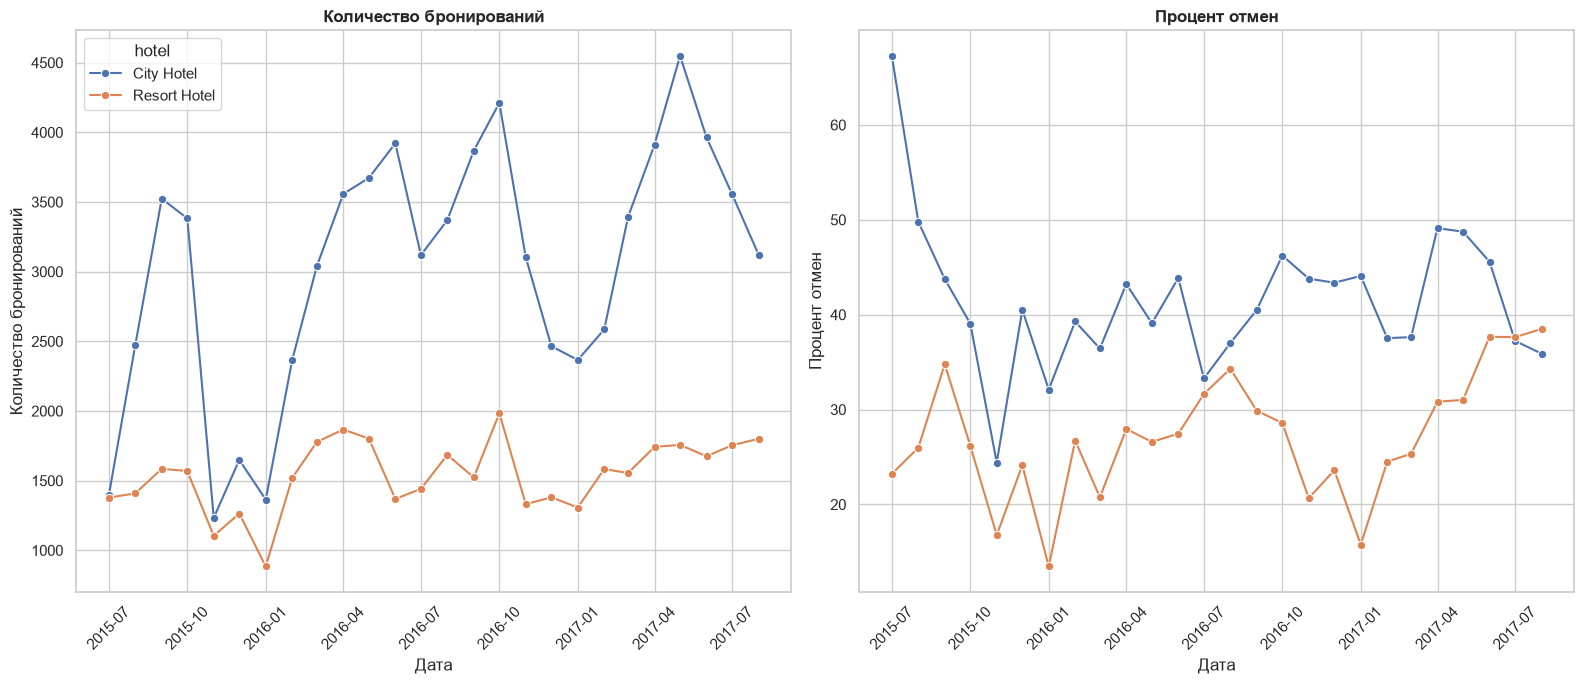

In [523]:
plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1)
sns.lineplot(data=grouped_time_hotel, 
            x='arrival_period', 
            y='count_booking',
            hue='hotel',
            palette='deep',
            marker='o')
plt.title('Количество бронирований',
          fontweight="bold")
plt.xlabel("Дата")
plt.ylabel("Количество бронирований")
plt.xticks(rotation=45)

plt.subplot(1, 2, 2)
sns.lineplot(data=grouped_time_hotel,
            x='arrival_period',
            y='canceled_rate',
            hue='hotel',
            palette='deep',
            marker='o',
            legend=False
)
plt.title('Процент отмен',
          fontweight="bold")
plt.xlabel("Дата")
plt.ylabel("Процент отмен")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Вывод:** City Hotel почти во все месяцы получает больше бронирований и имеет более высокую долю отмен.

### 10.2. ADR и стоимость неотменённых бронирований

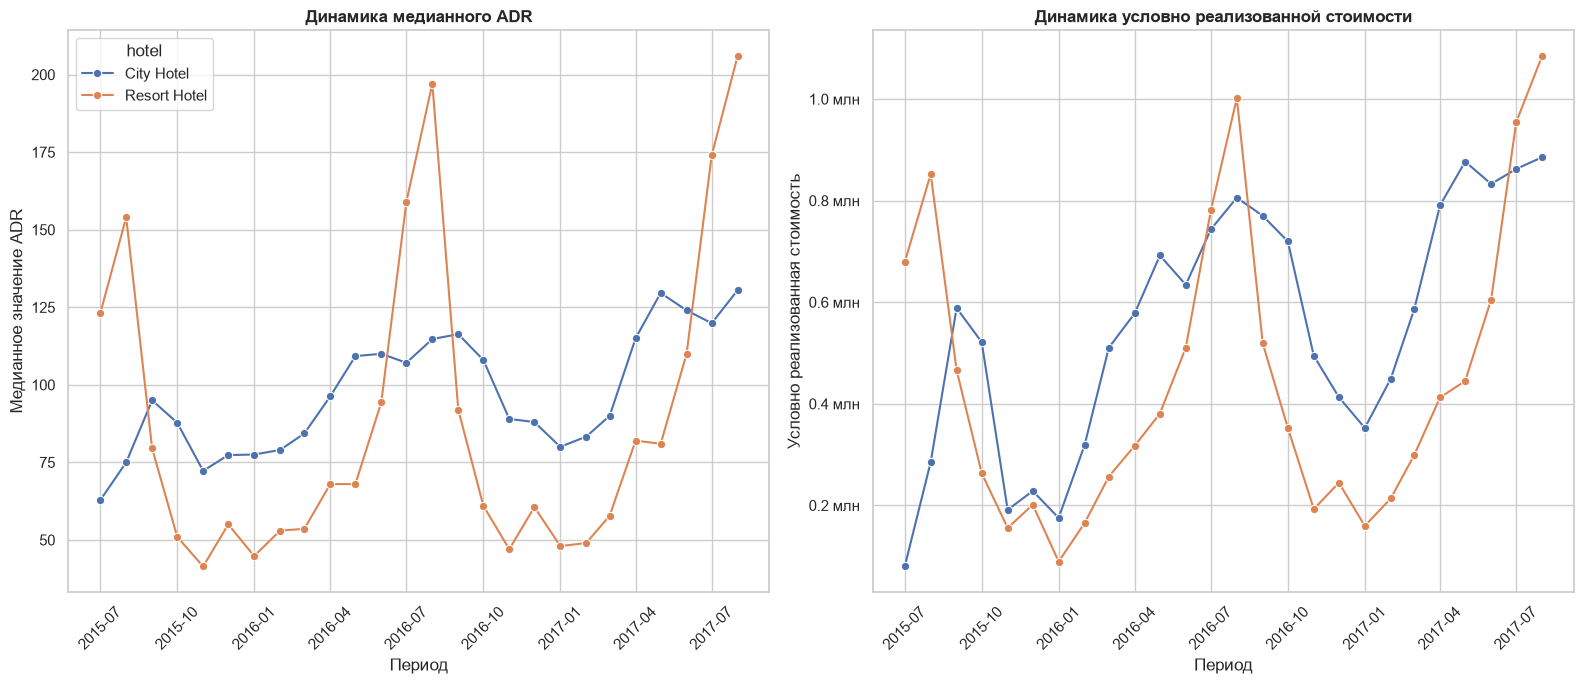

In [524]:
from matplotlib.ticker import FuncFormatter

plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1)
ax1 = sns.lineplot(data=grouped_time_hotel,
            x='arrival_period',
            y='median_adr',
            marker='o',
            hue='hotel',
            palette='deep',
            )
plt.xlabel("Период")
plt.xticks(rotation=45)
plt.ylabel("Медианное значение ADR")
plt.title("Динамика медианного ADR",
          fontweight="bold")

plt.subplot(1, 2, 2)
ax2 = sns.lineplot(data=grouped_time_hotel,
             x='arrival_period',
             y='sum_proxy',
             hue='hotel',
             palette='deep',
             marker='o',
             legend=False,
             errorbar=None
             )
ax2.yaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"{value / 1_000_000:.1f} млн")
)
plt.xlabel("Период")
plt.xticks(rotation=45)
plt.ylabel("Условно реализованная стоимость")
plt.title('Динамика условно реализованной стоимости', 
          fontweight="bold",
          )

plt.tight_layout()
plt.show()


**Вывод:** сезонность ADR сильнее в Resort Hotel. Максимальная стоимость неотменённых бронирований у обоих отелей приходится на август 2017 года.

## 11. Рыночные сегменты

In [525]:
grouped_market_segment = analyst_df.groupby('market_segment').agg(
                        bookings=('market_segment', 'size'),
                        canceled_bookings=('is_canceled', 'sum'),
                        median_adr=('adr', 'median'),
                        proxy_revenue=('proxy_revenue', 'sum'),
                        mean_lead_time=('lead_time', 'mean')
).reset_index()

grouped_market_segment['canceled_rate'] = grouped_market_segment['canceled_bookings'] / grouped_market_segment['bookings'] * 100
grouped_market_segment.sort_values('bookings', ascending=False, inplace=True, )

In [526]:
grouped_market_segment

,market_segment,bookings,canceled_bookings,median_adr,proxy_revenue,mean_lead_time,canceled_rate
6,Online TA,56408,20735,109.80,"13,707,139.09",83.07,36.76
5,Offline TA/TO,24182,8302,85.50,"5,659,291.94",135.10,34.33
4,Groups,19790,12094,70.00,"1,869,129.52",187.09,61.11
3,Direct,12582,1934,105.00,"4,097,842.40",49.90,15.37
2,Corporate,5282,991,65.00,"577,892.19",22.14,18.76
1,Complementary,728,89,0.00,"4,812.53",13.55,12.23
0,Aviation,235,52,95.00,"70,868.36",4.47,22.13
7,Undefined,2,2,15.00,0.00,1.50,100.00


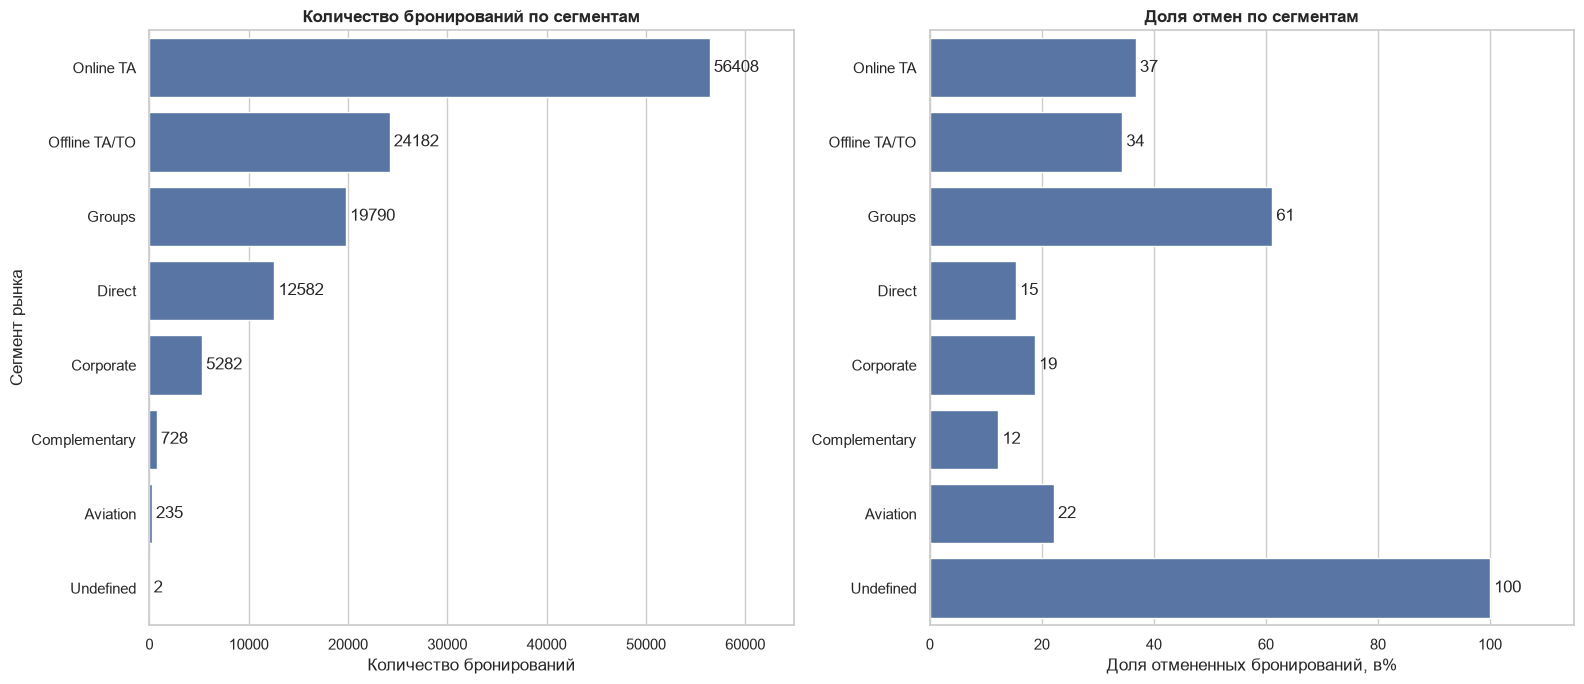

In [527]:
segment_order = grouped_market_segment["market_segment"].tolist()
plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1)
ax1 = sns.barplot(data=grouped_market_segment,
             x='bookings',
             y='market_segment',
             errorbar=None,
             order=segment_order,
)
ax1.bar_label(
    ax1.containers[0],
    fmt="%.0f",
    padding=3
)
ax1.set_xlim(0, grouped_market_segment["bookings"].max() * 1.15)
plt.xlabel("Количество бронирований")
plt.ylabel("Сегмент рынка")
plt.title("Количество бронирований по сегментам",
           fontweight="bold")

plt.subplot(1, 2, 2)
ax2 = sns.barplot(data=grouped_market_segment,
            x='canceled_rate',
            y='market_segment',
            errorbar=None,
            order=segment_order)
ax2.bar_label(
    ax2.containers[0],
    fmt="%.0f",
    padding=3
)

plt.xlabel("Доля отмененных бронирований, в%")
plt.ylabel("")
plt.title("Доля отмен по сегментам",
          fontweight="bold")
ax2.set_xlim(0, grouped_market_segment["canceled_rate"].max() * 1.15)
plt.tight_layout()
plt.show()

**Вывод:** `Online TA` — крупнейший сегмент: 56,4 тыс. бронирований и 36,8% отмен. У `Groups` отмен больше всего среди крупных сегментов — 61,1% при 19,8 тыс. бронирований. Категорию `Undefined` интерпретировать не будем: в ней только 2 строки.

## 12. Тип депозита

In [528]:
group_deposit_type = analyst_df.groupby(by='deposit_type').agg(
    bookings=('deposit_type', 'size'),
    canceled_booking=('is_canceled', 'sum'),
    median_adr=('adr', 'median'),
    median_lead_time=('lead_time', 'median'),
    proxy_revenue=('proxy_revenue', 'sum')
).reset_index()
group_deposit_type['canceled_rate'] = group_deposit_type['canceled_booking'] / group_deposit_type['bookings'] * 100
group_deposit_type.sort_values('bookings', ascending=False, inplace=True)


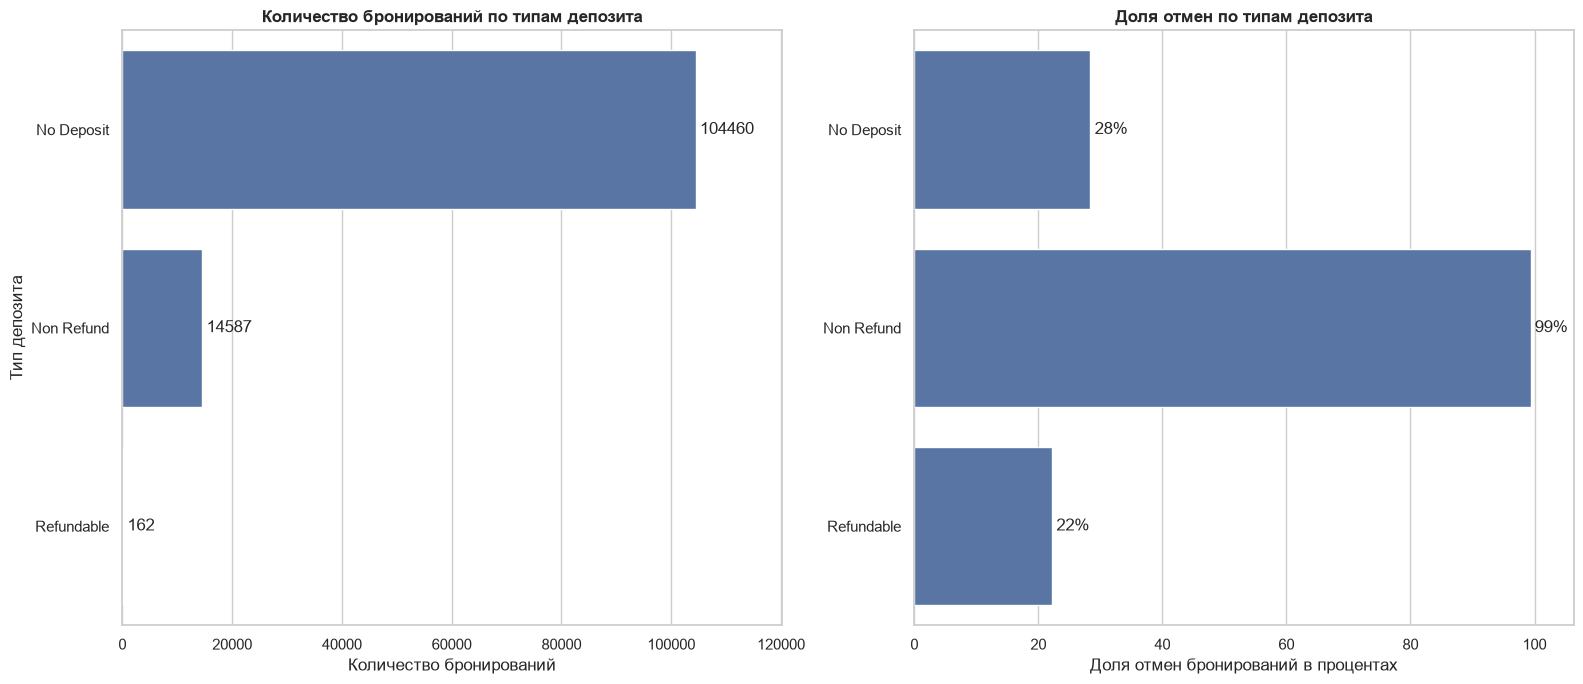

In [529]:
type_deposit = group_deposit_type['deposit_type'].tolist()
plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1)
ax1 = sns.barplot(data=group_deposit_type,
            x='bookings',
            y='deposit_type',
            order=type_deposit,
            errorbar=None)
ax1.bar_label(
    ax1.containers[0],
    fmt="%.0f",
    padding=3
)
ax1.set_xlim(0, group_deposit_type['bookings'].max() * 1.15)
plt.xlabel("Количество бронирований")
plt.ylabel("Тип депозита")
plt.title("Количество бронирований по типам депозита",
           fontweight="bold")

plt.subplot(1, 2, 2)
ax2 = sns.barplot(data=group_deposit_type,
            x='canceled_rate',
            y='deposit_type',
            order=type_deposit,
            errorbar=None)
ax2.bar_label(
    ax2.containers[0],
    fmt='%.0f%%',
    padding=3
)
ax2.set_xlim(0, group_deposit_type['canceled_rate'].max() * 1.07)
plt.xlabel("Доля отмен бронирований в процентах")
plt.ylabel("")
plt.title("Доля отмен по типам депозита",
          fontweight="bold")

plt.tight_layout()
plt.show()


**Вывод:** у `No Deposit` 28,4% отмен, у `Non Refund` — 99,4%. Результат для `Non Refund` требует отдельной проверки: он показывает связь, но не доказывает, что депозит вызывает отмену. В `Refundable` только 162 бронирования.

## 13. Срок бронирования

In [530]:
def group_of_lead_time(x):
    if 0 <= x <= 7:
        return "0–7 дней"
    elif x <= 30:
        return "8–30 дней"
    elif x <= 90:
        return "31–90 дней"
    elif x <= 180:
        return "91–180 дней"
    else:
        return "Более 180 дней"

analyst_df['lead_time_group'] = analyst_df['lead_time'].apply(group_of_lead_time)

In [531]:
group_lead_time = analyst_df.groupby('lead_time_group').agg(
    bookings=('lead_time_group', 'size'),
    canceled_booking=('is_canceled', 'sum'),
    median_adr=('adr', 'median'),
    proxy_revenue=('proxy_revenue', 'sum')
).reset_index()
group_lead_time['canceled_rate'] = group_lead_time['canceled_booking'] / group_lead_time['bookings'] * 100

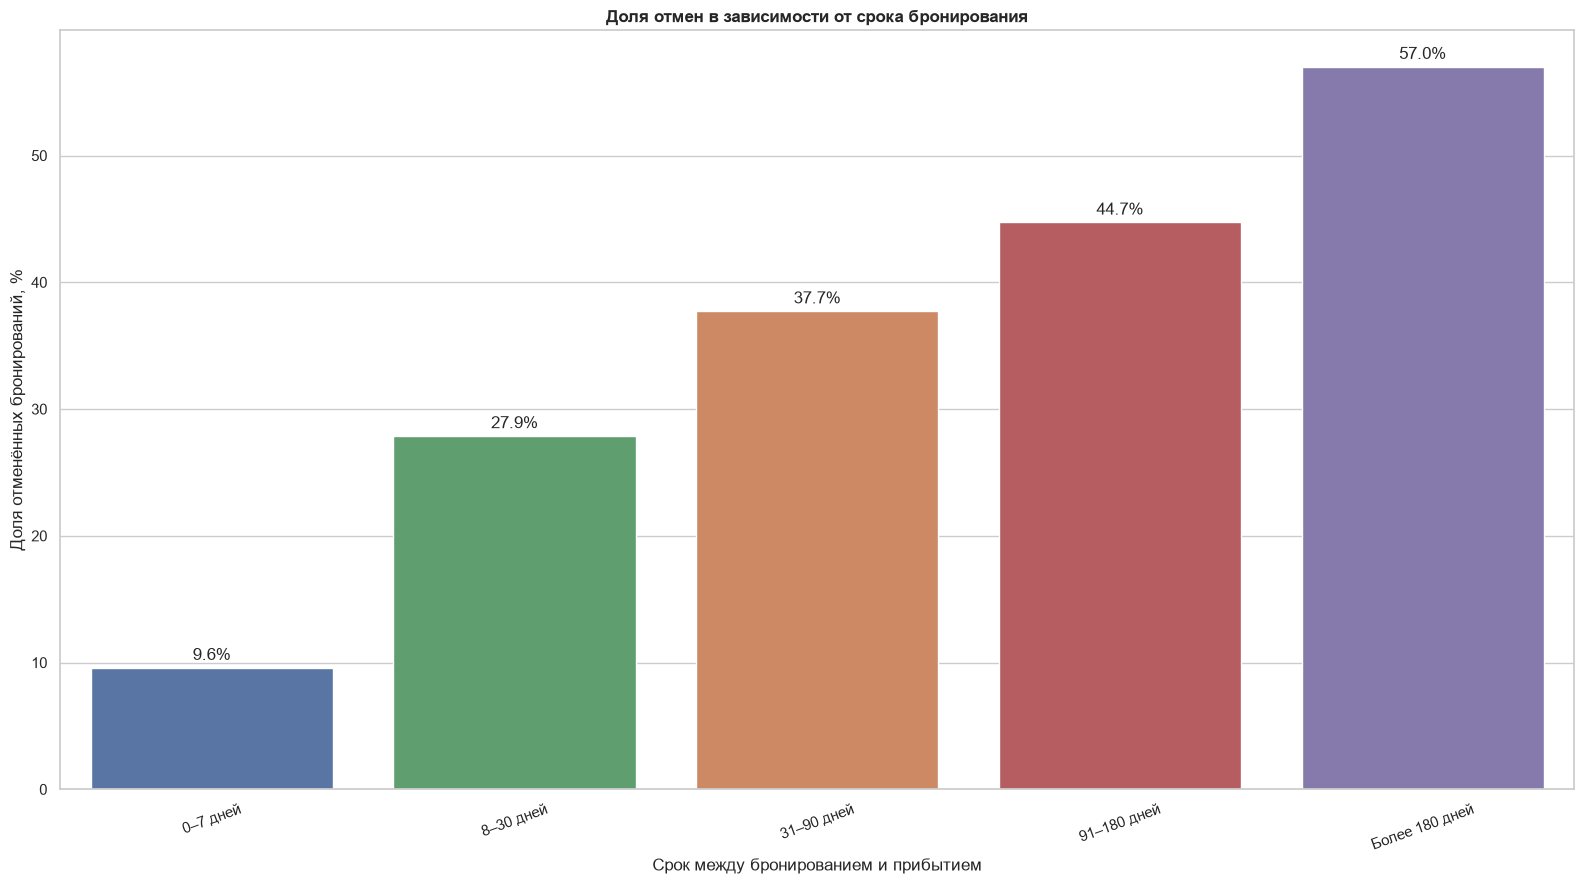

In [532]:
lead_time_order = [
    "0–7 дней",
    "8–30 дней",
    "31–90 дней",
    "91–180 дней",
    "Более 180 дней"
]
plt.figure(figsize=(16, 9))
ax1 = sns.barplot(data=group_lead_time,
            x='lead_time_group',
            y='canceled_rate',
            order=lead_time_order,
            hue = 'lead_time_group',
            palette='deep',
            errorbar=None)
for container in ax1.containers:
    ax1.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
)
plt.xlabel("Срок между бронированием и прибытием")
plt.xticks(rotation=20)
plt.ylabel("Доля отменённых бронирований, %")
plt.title("Доля отмен в зависимости от срока бронирования",
           fontweight="bold")
plt.tight_layout()
plt.show()

**Вывод:** доля отмен растёт вместе с `lead_time`: от 9,6% для бронирований за 0–7 дней до 57,0% для срока более 180 дней.

## 14. Тип клиента

In [533]:
group_customer_type = analyst_df.groupby(by='customer_type').agg(
                            bookings=('customer_type', 'size'),
                            canceled_bookings=('is_canceled', 'sum'),
                            median_adr=('adr', 'median'),
                            mean_nights=('total_nights', 'mean'),
                            median_lead_time=('lead_time', 'median'),
                            proxy_revenue=('proxy_revenue', 'sum')
).reset_index()
group_customer_type['canceled_rate'] = group_customer_type['canceled_bookings'] / group_customer_type['bookings'] * 100

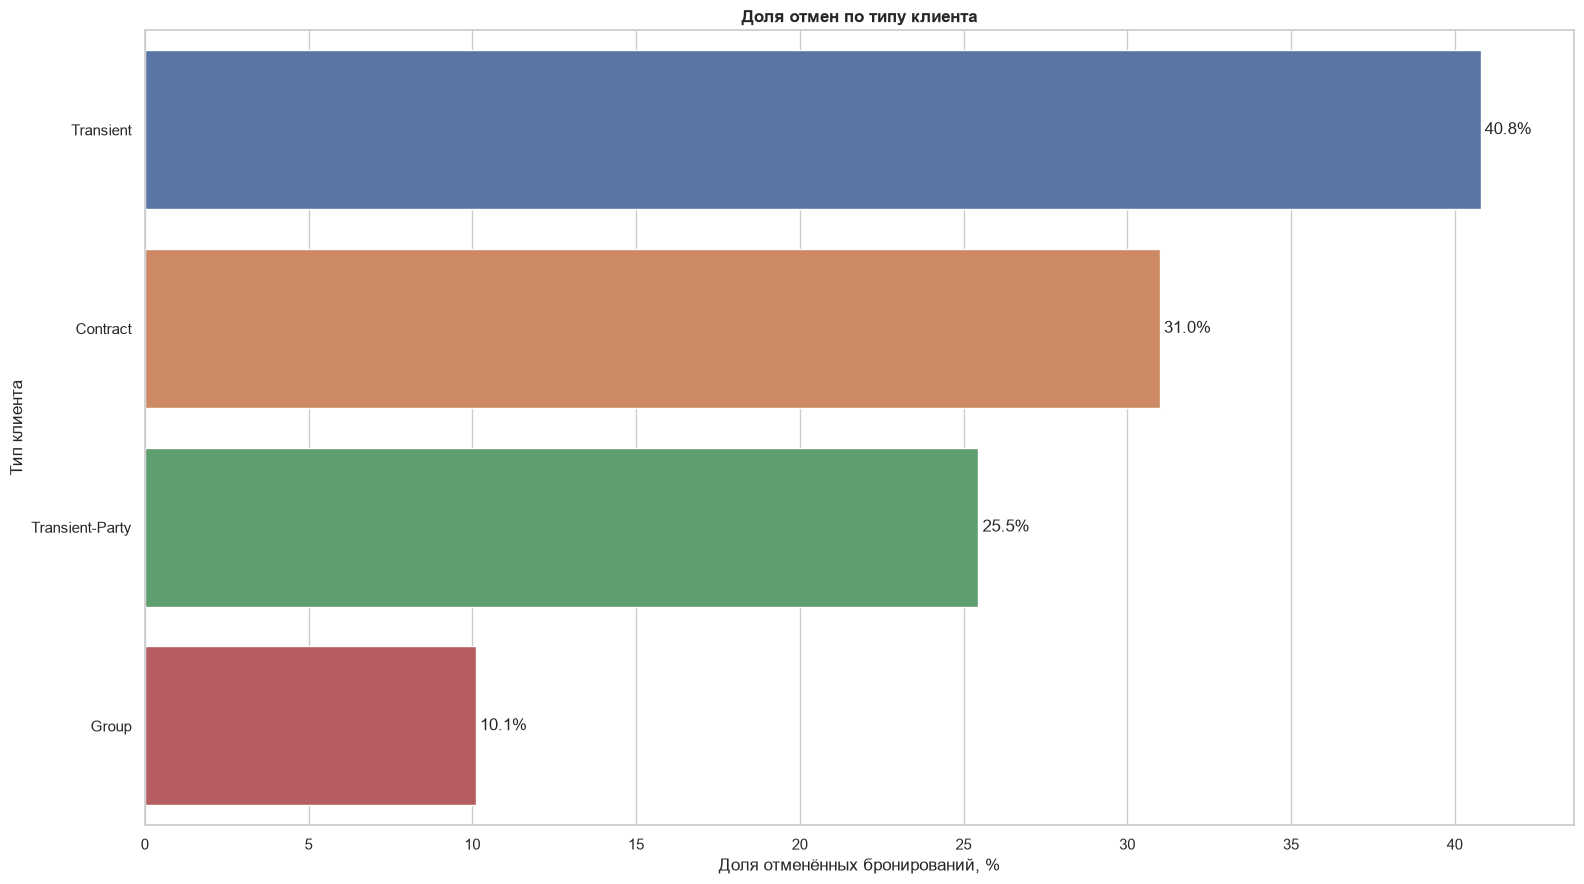

In [534]:
group_customer_type.sort_values('canceled_rate', ascending=False, inplace=True)
customer_order = group_customer_type["customer_type"].tolist()
plt.figure(figsize=(16, 9))
ax1 = sns.barplot(data=group_customer_type,
            x='canceled_rate',
            y='customer_type',
            order=customer_order,
            hue='customer_type',
            hue_order=customer_order,
            legend=False,
            palette='deep',
            errorbar=None)
for container in ax1.containers:
    ax1.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
)
ax1.set_xlim(0, group_customer_type['canceled_rate'].max() * 1.07)
plt.xlabel("Доля отменённых бронирований, %")
plt.ylabel("Тип клиента")
plt.title("Доля отмен по типу клиента",
           fontweight="bold")
plt.tight_layout()
plt.show()

**Вывод:** `Transient` — крупнейшая группа (89,5 тыс.) и лидер по доле отмен (40,8%). Далее идут `Contract` (31,0%), `Transient-Party` (25,5%) и `Group` (10,1%).

## 15. Специальные запросы

In [535]:
group_total_request = analyst_df.groupby(by='total_of_special_requests').agg(
                            bookings=('total_of_special_requests', 'size'),
                            canceled_bookings=('is_canceled', 'sum'),
                            median_adr=('adr', 'median'),
                            median_lead_time=('lead_time', 'median'),
                            proxy_revenue=('proxy_revenue', 'sum')
).reset_index()
group_total_request['canceled_rate'] = group_total_request['canceled_bookings'] / group_total_request['bookings'] * 100
group_total_request.sort_values('total_of_special_requests', ascending=True, inplace=True)

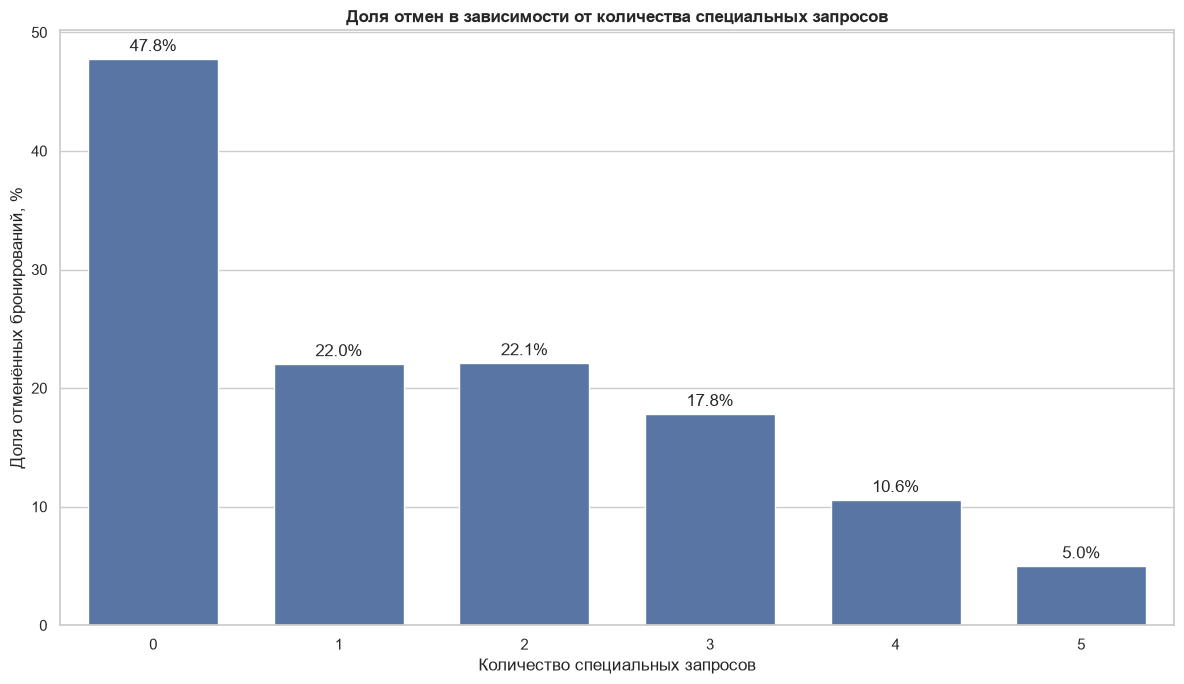

In [536]:
plt.figure(figsize=(12, 7))
ax1 = sns.barplot(data=group_total_request,
            x='total_of_special_requests',
            y='canceled_rate',
            width=0.7,
            errorbar=None)
for container in ax1.containers:
    ax1.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
)
plt.xlabel("Количество специальных запросов")
plt.ylabel("Доля отменённых бронирований, %")
plt.title("Доля отмен в зависимости от количества специальных запросов",
           fontweight="bold")
plt.tight_layout()
plt.show()

**Вывод:** без специальных запросов отменяется 47,8% бронирований. При одном или двух запросах — около 22%. Группы с 4–5 запросами маленькие, поэтому их проценты менее устойчивы.

## 16. Предыдущие отмены

In [537]:
def group_of_count_cancel(x):
    if x == 0:
        return "0 отмен"
    elif x == 1:
        return "1 отмена"
    else:
        return "2 и более"

analyst_df['previous_cancellations_group'] = analyst_df['previous_cancellations'].apply(group_of_count_cancel)

In [538]:
group_previous_cancellations = analyst_df.groupby(by='previous_cancellations_group').agg(
                                bookings=('previous_cancellations_group', 'size'),
                                canceled_bookings=('is_canceled', 'sum'),
                                median_adr=('adr', 'median'),
                                median_lead_time=('lead_time', 'median'),
                                proxy_revenue=('proxy_revenue', 'sum')
).reset_index()
group_previous_cancellations ['canceled_rate'] = group_previous_cancellations ['canceled_bookings'] / group_previous_cancellations ['bookings'] * 100

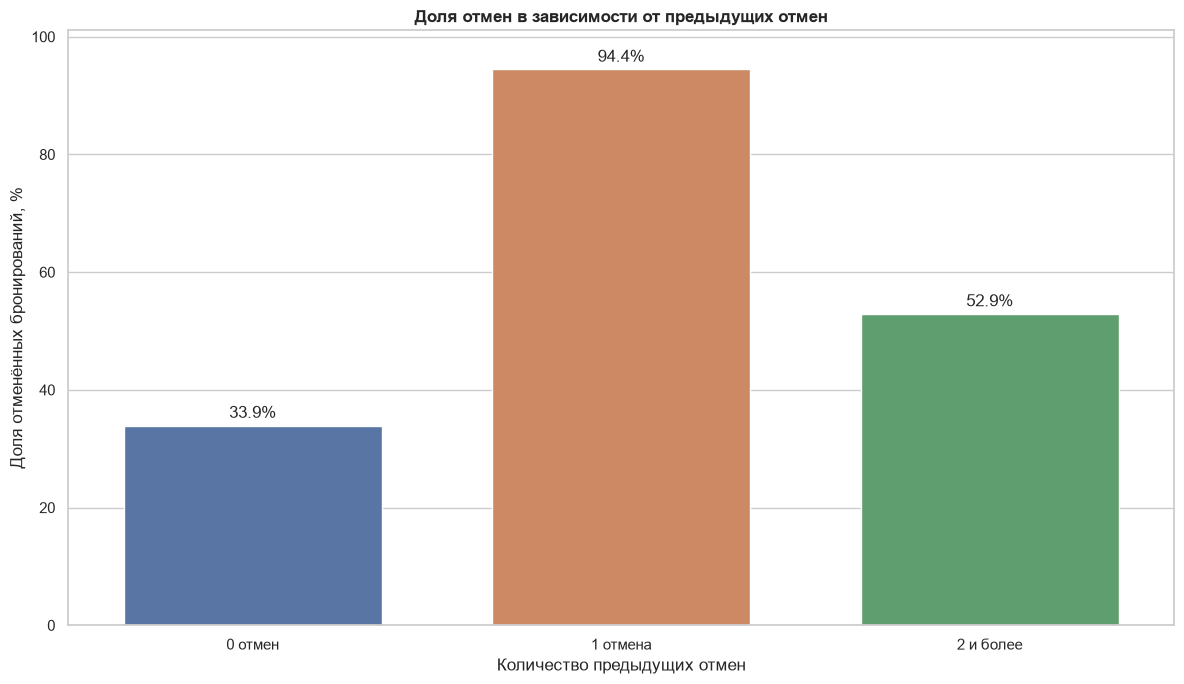

In [539]:
previous_order = [
        "0 отмен",
        "1 отмена",
        "2 и более"
]
plt.figure(figsize=(12, 7))
ax1 = sns.barplot(data=group_previous_cancellations,
            x='previous_cancellations_group',
            y='canceled_rate',
            hue='previous_cancellations_group',
            palette='deep',
            order=previous_order,
            width=0.7,
            errorbar=None)
for container in ax1.containers:
    ax1.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
)
ax1.set_ylim(0, group_previous_cancellations['canceled_rate'].max()*1.07)
plt.xlabel("Количество предыдущих отмен")
plt.ylabel("Доля отменённых бронирований, %")
plt.title("Доля отмен в зависимости от предыдущих отмен",
           fontweight="bold")
plt.tight_layout()
plt.show()

**Вывод:** без предыдущих отмен текущая доля отмен равна 33,9%, после одной отмены — 94,4%. В группе «2 и более» только 431 бронирование, поэтому её результат нужно трактовать осторожно.

## 17. `lead_time` по статусу бронирования

На boxplot выбросы скрыты только для читаемости, из данных они не удалены.

In [540]:
def cancel(x):
    if x == 0:
        return "Состоялось"
    else:
        return "Отменено"

analyst_df['cancel_or_not'] = analyst_df['is_canceled'].apply(cancel)

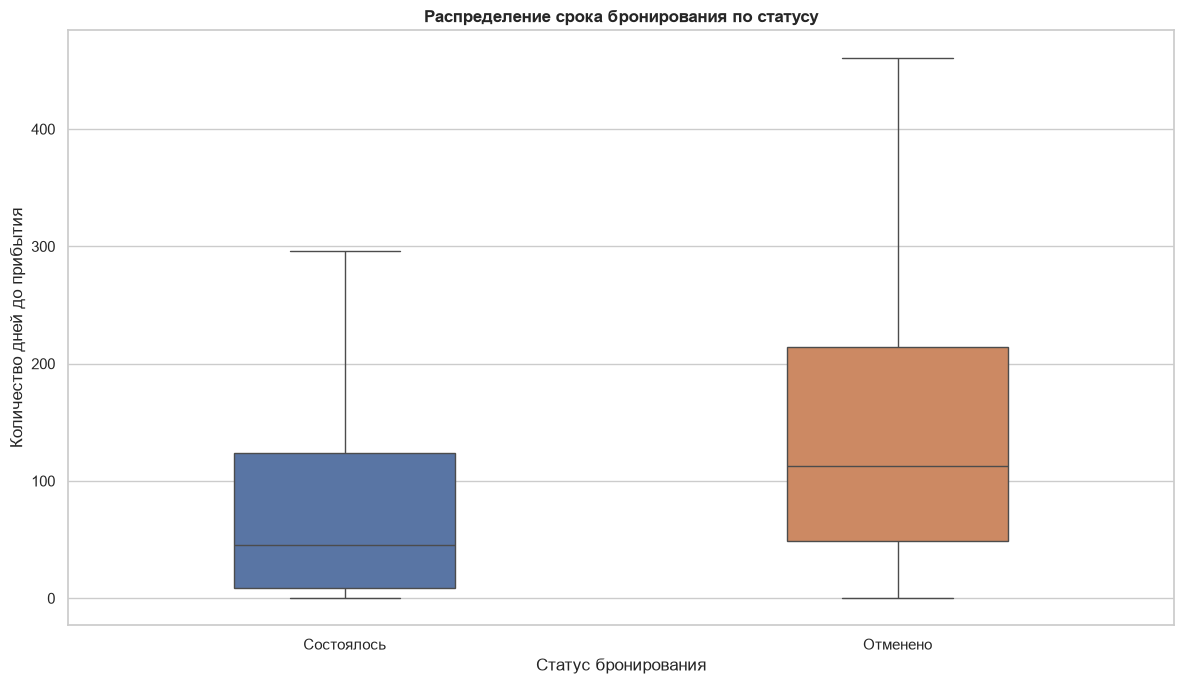

In [541]:
plt.figure(figsize=(12, 7))
ax1 = sns.boxplot(data=analyst_df,
            x='cancel_or_not',
            y='lead_time',
            hue='cancel_or_not',
            palette='deep',
            showfliers=False,
            width=0.4
)
plt.xlabel("Статус бронирования")
plt.ylabel("Количество дней до прибытия")
plt.title("Распределение срока бронирования по статусу",
           fontweight="bold")
plt.tight_layout()
plt.show()

**Вывод:** медианный `lead_time` отменённых бронирований равен 113 дням, состоявшихся — 45 дням.

## 18. Итоги EDA

С повышенной долей отмен связаны:

- City Hotel;
- сегмент `Groups`;
- депозит `Non Refund`;
- большой `lead_time`;
- тип клиента `Transient`;
- отсутствие специальных запросов;
- предыдущие отмены.

Далее проверим основные различия статистически.

## 19. Статистическая проверка

### 19.1. `lead_time` и отмена

На графике разница заметна. Проверим её статистически.

- **H0:** средний `lead_time` в группах одинаковый;
- **H1:** средний `lead_time` различается;
- уровень значимости — 0,05.

In [542]:
lead_time_complete = analyst_df.loc[analyst_df['is_canceled'] == 0, 'lead_time'].dropna()
lead_time_cancel = analyst_df.loc[analyst_df['is_canceled'] == 1, 'lead_time'].dropna()

In [543]:
alpha = 0.05


In [544]:
count_view_complete = lead_time_complete.count()
mean_complete = lead_time_complete.mean()
median_complete = lead_time_complete.median()
std_complete = lead_time_complete.std(ddof=1)
q1_complete = lead_time_complete.quantile(0.25)
q3_complete = lead_time_complete.quantile(0.75)
a3_complete = lead_time_complete.skew()

count_view_cancel = lead_time_cancel.count()
mean_cancel = lead_time_cancel.mean()
median_cancel = lead_time_cancel.median()
std_cancel = lead_time_cancel.std(ddof=1)
q1_cancel = lead_time_cancel.quantile(0.25)
q3_cancel = lead_time_cancel.quantile(0.75)
a3_cancel = lead_time_cancel.skew()
arr3 = [[count_view_complete, mean_complete, median_complete, std_complete,
         q1_complete, q3_complete, a3_complete],
        [count_view_cancel, mean_cancel, median_cancel, std_cancel,
         q1_cancel, q3_cancel, a3_cancel]]
lead_time_df = pd.DataFrame(arr3, columns=['Количество наблюдений', 'Mean', 'Median', 'Std', 'q1', 'q3', 'Коэффициент асимметрии'], index=['состоялось', 'не состоялось'])

In [545]:
lead_time_df 

,Количество наблюдений,Mean,Median,Std,q1,q3,Коэффициент асимметрии
состоялось,75010,80.08,45.00,91.14,9.00,124.00,1.53
не состоялось,44199,144.89,113.00,118.61,49.00,214.00,1.03


Сначала проверим нормальность критерием Лиллиефорса.

- **H0:** распределение нормальное;
- **H1:** распределение отличается от нормального.

Выборки большие, поэтому тест чувствителен даже к небольшим отклонениям.

In [546]:
from statsmodels.stats.diagnostic import lilliefors

In [547]:
ks_complete, p_complete = lilliefors(
    lead_time_complete,
    dist="norm",
    pvalmethod="table"
)
ks_cancel, p_cancel = lilliefors(
    lead_time_cancel,
    dist='norm',
    pvalmethod="table"
)
if  p_complete < alpha:
    print("Распределение состоявшихся бронирований отличается от нормального, отвергаем H0")
else:
    print("не отвергаем H0 о нормальности распределения")

if  p_cancel < alpha:
    print("Распределение отмененных бронирований отличается от нормального, отвергаем H0")
else:
    print("не отвергаем H0 о нормальности распределения")

print(f"Состоялось: D = {ks_complete:.4f}, p-value = {p_complete:.4f}")
print(f"Отменено: D = {ks_cancel:.4f}, p-value = {p_cancel:.4f}")


Распределение состоявшихся бронирований отличается от нормального, отвергаем H0
Распределение отмененных бронирований отличается от нормального, отвергаем H0
Состоялось: D = 0.1898, p-value = 0.0010
Отменено: D = 0.1109, p-value = 0.0010


В обеих группах `p ≤ 0,001`, поэтому гипотезу о нормальности отвергнем. Распределения имеют правую асимметрию.

Далее проверим равенство дисперсий тестом Левена с центром по медиане.

In [548]:
from scipy import stats
sl, p_value = stats.levene(lead_time_complete,
                           lead_time_cancel,
                           center="median")

if p_value < alpha:
    print("Отвергаем гипотезу о равенстве дисперсий")
else:
    print("Недостаточно оснований отвергнуть гипотезу о равенстве дисперсий")

print(f'Статистика Левена: {sl:.4f}')
print('p-value < 0.001' if p_value < 0.001 else f'p-value = {p_value:.3f}')
print(f"Отношение дисперсий 2 групп = {lead_time_cancel.var() / lead_time_complete.var():.4f}")

Отвергаем гипотезу о равенстве дисперсий
Статистика Левена: 3580.6427
p-value < 0.001
Отношение дисперсий 2 групп = 1.6938


In [549]:
t, p_val = stats.ttest_ind(lead_time_cancel, 
                           lead_time_complete,
                           equal_var=False,
                           alternative="two-sided")
if p_val < alpha:
    print("Отвергаем гипотезу о равенстве средних 2 групп")
else:
    print("Недостаточно оснований отвергнуть гипотезу о равенстве средних 2 групп")

print(f't-статистика: {t:.4f}')
print('p-value < 0.001' if p_val < 0.001 else f'p-value = {p_val:.3f}')
print(f'Разница средних: {lead_time_cancel.mean() - lead_time_complete.mean()}')

Отвергаем гипотезу о равенстве средних 2 групп
t-статистика: 98.9387
p-value < 0.001
Разница средних: 64.80576846124657


Тест Левена дал `p < 0,001`, отношение дисперсий равно 1,69. Поэтому будем использовать t-тест Уэлча, который не требует равенства дисперсий.

По t-тесту `p < 0,001`: средний `lead_time` отменённых бронирований выше на 64,81 дня. Далее оценим размер эффекта и проверим результат критерием Манна—Уитни.

In [550]:
n_complete = count_view_complete 
n_cancel = count_view_cancel
pooled_std = np.sqrt(((n_complete - 1) * std_complete**2 + (n_cancel - 1) * std_cancel**2) / (n_cancel + n_complete - 2))
coh = (mean_cancel - mean_complete) / pooled_std
print('n_complete: ', n_complete)
print('n_cancel: ', n_cancel)
print('std_complete: ', std_complete)
print('std_cancel: ', std_cancel)
print('pooled_std: ', pooled_std)
print(f"Cohen's d: {coh:.3f}")

n_complete:  75010
n_cancel:  44199
std_complete:  91.13743831317552
std_cancel:  118.61179547754301
pooled_std:  102.18933410589037
Cohen's d: 0.634


In [551]:
u, p_val_u = stats.mannwhitneyu(lead_time_cancel,
                                lead_time_complete,
                                alternative="two-sided",
                                method="asymptotic")
if p_val_u < alpha:
    print("Отвергаем гипотезу о том, что в 2 выборках одно и то же распределение")
else:
    print("Недостаточно оснований отвергнуть гипотезу о том, что в 2 выборках одно и то же распределение")

print(f'U-статистика: {u:.0f}')
print('p-value < 0.001' if p_val_u < 0.001 else f'p-value = {p_val_u:.3f}')
rb = 2 * u / (n_complete * n_cancel) - 1
print(f'Значение рангово-бисериальной корреляции: {rb}')


Отвергаем гипотезу о том, что в 2 выборках одно и то же распределение
U-статистика: 2284666098
p-value < 0.001
Значение рангово-бисериальной корреляции: 0.3782281749749823


Cohen’s d равен 0,63 — эффект среднего размера. Критерий Манна—Уитни также показал различие (`p < 0,001`), рангово-бисериальная корреляция равна 0,38.

Манн—Уитни сравнивает распределения и ранги, а не только медианы. Для оценки точности разницы дополнительно построим бутстрэп-интервалы.

In [552]:
n_boot = 1000
np.random.seed(42)
arr_diff_mean = []
arr_diff_median = []
for _ in range(n_boot):
    bootstrap_sample_cancel = np.random.choice(
        lead_time_cancel,
        size=n_cancel,
        replace=True
    )
    bootstrap_sample_complete = np.random.choice(
        lead_time_complete,
        size=n_complete,
        replace=True
    )
    arr_diff_mean.append(bootstrap_sample_cancel.mean() - bootstrap_sample_complete.mean())
    arr_diff_median.append(np.median(bootstrap_sample_cancel) - np.median(bootstrap_sample_complete))

In [553]:
mean_diff = mean_cancel - mean_complete
median_diff = median_cancel - median_complete

In [554]:
low_mean, high_mean = np.percentile(arr_diff_mean, [2.5, 97.5])
low_median, high_median = np.percentile(arr_diff_median, [2.5, 97.5])

In [555]:

print(f"Разница средних: {mean_diff:.2f} дня")
print(
    f"95% ДИ для разницы средних: "
    f"[{low_mean:.2f}; {high_mean:.2f}]"
)

print(f"Разница медиан: {median_diff:.2f} дня")
print(
    f"95% ДИ для разницы медиан: "
    f"[{low_median:.2f}; {high_median:.2f}]"
)

Разница средних: 64.81 дня
95% ДИ для разницы средних: [63.51; 66.02]
Разница медиан: 68.00 дня
95% ДИ для разницы медиан: [67.00; 70.00]


In [556]:
if low_mean <= 0 <= high_mean:
    print("Доверительный интервал разницы средних включает ноль.")
else:
    print("Доверительный интервал разницы средних не включает ноль.")

if low_median <= 0 <= high_median:
    print("Доверительный интервал разницы медиан включает ноль.")
else:
    print("Доверительный интервал разницы медиан не включает ноль.")

Доверительный интервал разницы средних не включает ноль.
Доверительный интервал разницы медиан не включает ноль.


**Вывод по `lead_time`:**

- разница средних — 64,81 дня, 95% ДИ `[63,51; 66,02]`;
- разница медиан — 68 дней, 95% ДИ `[67; 70]`.

Оба интервала не содержат ноль. Отменённые бронирования делают за больший срок до заезда.

### 19.2. Тип депозита и отмена

Проверим связь критерием хи-квадрат.

- **H0:** тип депозита и отмена независимы;
- **H1:** между ними есть связь.

Силу связи оценим коэффициентом Крамера V.

In [557]:
deposit_table = pd.crosstab(
    analyst_df['deposit_type'],
    analyst_df['is_canceled']
)
deposit_table.columns = ['Состоялось', 'Отменено']
deposit_table

,Состоялось,Отменено
deposit_type,,
No Deposit,74791,29669
Non Refund,93,14494
Refundable,126,36


In [558]:
chi2_deposit, p_deposit, dof_deposit, expected_deposit = stats.chi2_contingency(deposit_table)

n_deposit = deposit_table.to_numpy().sum()
rows_deposit, cols_deposit = deposit_table.shape
cramers_v_deposit = np.sqrt(
    chi2_deposit / (n_deposit * min(rows_deposit - 1, cols_deposit - 1))
)

print(f"Хи-квадрат: {chi2_deposit:.2f}")
print(f"Степени свободы: {dof_deposit}")
print("p-value < 0.001" if p_deposit < 0.001 else f"p-value = {p_deposit:.3f}")
print(f"Минимальная ожидаемая частота: {expected_deposit.min():.2f}")
print(f"Коэффициент Крамера V: {cramers_v_deposit:.3f}")

Хи-квадрат: 27641.06
Степени свободы: 2
p-value < 0.001
Минимальная ожидаемая частота: 60.06
Коэффициент Крамера V: 0.482


**Вывод:** тип депозита связан с отменой: χ²(2) = 27 641,06, `p < 0,001`, Крамер V = 0,482. Связь заметная. У `Non Refund` отменено 99,4% бронирований, но по этим данным нельзя утверждать, что именно депозит стал причиной отмены.

### 19.3. Тип отеля и отмена

Проверим, связан ли тип отеля со статусом бронирования. Гипотезы будут такими же: независимость против наличия связи.

In [559]:
hotel_table = pd.crosstab(
    analyst_df['hotel'],
    analyst_df['is_canceled']
)
hotel_table.columns = ['Состоялось', 'Отменено']
hotel_table

,Состоялось,Отменено
hotel,,
City Hotel,46084,33079
Resort Hotel,28926,11120


In [560]:
chi2_hotel, p_hotel, dof_hotel, expected_hotel = stats.chi2_contingency(hotel_table)

n_hotel = hotel_table.to_numpy().sum()
rows_hotel, cols_hotel = hotel_table.shape
cramers_v_hotel = np.sqrt(
    chi2_hotel / (n_hotel * min(rows_hotel - 1, cols_hotel - 1))
)

print(f"Хи-квадрат: {chi2_hotel:.2f}")
print(f"Степени свободы: {dof_hotel}")
print("p-value < 0.001" if p_hotel < 0.001 else f"p-value = {p_hotel:.3f}")
print(f"Минимальная ожидаемая частота: {expected_hotel.min():.2f}")
print(f"Коэффициент Крамера V: {cramers_v_hotel:.3f}")

Хи-квадрат: 2239.27
Степени свободы: 1
p-value < 0.001
Минимальная ожидаемая частота: 14847.81
Коэффициент Крамера V: 0.137


**Вывод:** тип отеля связан с отменой: χ²(1) = 2 239,27, `p < 0,001`, Крамер V = 0,137. Связь слабая. При большом объёме данных p-value легко становится маленьким, поэтому здесь важнее размер эффекта.

## 20. Итоги проекта

### Главное

- отменено **37,1%** бронирований;
- City Hotel отменяют чаще: **41,8%** против **27,8%**;
- стоимость неотменённых бронирований составляет **60,8%** потенциальной стоимости;
- у `Groups` высокая доля отмен — **61,1%**;
- у `Non Refund` отменено **99,4%** бронирований;
- при `lead_time` более 180 дней доля отмен достигает **57,0%**;
- отсутствие специальных запросов и предыдущие отмены связаны с повышенным риском.

### Что можно сделать

1. Настроим напоминания и повторное подтверждение бронирований с большим `lead_time`.
2. Проверим процесс оформления `Non Refund`: результат слишком высокий и требует отдельного разбора.
3. Сосредоточимся на City Hotel, сегменте `Groups` и клиентах `Transient`.
4. Будем использовать предыдущие отмены и отсутствие специальных запросов как признаки для дополнительного контакта с гостем.

### Ограничения

- нет уникального ID, поэтому одинаковые строки оставлены;
- `proxy_revenue` — оценка, а не бухгалтерская выручка;
- анализ показывает связи, но не причины;
- данные относятся только к двум отелям и неполным периодам 2015 и 2017 годов.